# 03. Paper: TabPFN v2

논문: Hollmann, Müller, Purucker, Krishnakumar, Körfer, Hoo, Schirrmeister, Hutter, *Accurate predictions on small data with a tabular foundation model*, Nature 637, 319–326 (2025), [doi:10.1038/s41586-024-08328-6](https://doi.org/10.1038/s41586-024-08328-6). 본문은 CC BY 4.0으로 공개되어 있습니다([PMC11711098](https://pmc.ncbi.nlm.nih.gov/articles/PMC11711098/)).

[`02_tabpfn`](../02_tabpfn/03_tabpfn_paper_walkthrough.ipynb)의 TabPFN(이 노트북에서는 v1이라고 부릅니다)을 키운 후속작입니다. v1은 학습 행 1,000개, feature 100개까지의 분류만 했고, 범주형 feature와 결측값에 약했습니다. v2는 행 10,000개, feature 500개까지의 분류와 회귀를 forward pass 한 번으로 하고, 4시간 튜닝한 CatBoost·XGBoost·AutoGluon보다 좋은 성능을 냅니다.

구조는 [`01_two_way_attention_primer`](01_two_way_attention_primer.ipynb)에서, prior는 [`02_prior_primer`](02_prior_primer.ipynb)에서 다뤘습니다. 이 노트북은 논문을 본문 순서대로 정리하고, Methods의 세부를 덧붙입니다.

1. 한눈에 보기
2. PFN 복습
3. 표를 위한 아키텍처 (Methods "Details on the neural architecture")
4. 인과 모델로 만든 합성 데이터 (Methods "Details on the causal generative process")
5. 학습 (Methods "Training details")
6. 회귀 출력 (Methods "Regression details")
7. 추론 (Methods "Inference details")
8. 정성 분석 — toy 문제
9. 정량 분석 — benchmark
10. 강건성과 foundation model 기능
11. 한계
12. 이 저장소의 재현 계획
13. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

rng = np.random.default_rng(0)

## 1. 한눈에 보기

![TabPFN v2 Figure 1](images/tabpfn_v2_fig1.png)

*그림: 논문 Fig. 1 (Hollmann et al. 2025, [Nature 637:319](https://doi.org/10.1038/s41586-024-08328-6), CC BY 4.0). (a) 합성 데이터셋으로 한 번 학습하고, 실제 데이터셋에는 forward pass 한 번으로 예측합니다. 회귀에서도 값 하나가 아니라 분포를 냅니다. (b) 표의 칸 하나가 노드 하나이고, 층마다 feature attention(같은 행)과 sample attention(같은 열)을 거칩니다. 테스트 행(주황)은 학습 행에만 attend합니다. 예측은 테스트 행의 y 칸에서 읽어 piece-wise constant(Riemann) 분포로 바꿉니다.*

v1과 v2를 비교하면 다음과 같습니다.

| | v1 (ICLR 2023) | v2 (Nature 2025) | 이 노트북 |
|---|---|---|---|
| 과제 | 분류 | 분류 + 회귀 | 6절 |
| 평가한 데이터셋 크기 | 학습 행 1,000, feature 100 | 행 10,000, feature 500 | 9절 |
| 클래스 | 10개까지 | 10개까지 | 4절 |
| 범주형 feature, 결측값 | 약함 | prior에 넣어 학습 | 4절 |
| 토큰 | 행 하나 | 셀 하나 (기본은 셀 2개) | 3절 |
| attention | 행 사이 | feature 사이 → 행 사이 번갈아 | 3절 |
| prior | MLP 모양 SCM + BNN | GNR 그래프 SCM (신경망·나무·이산화 간선) | 4절 |
| 학습 | 18,000 step × 512 = 약 920만 데이터셋 | 약 200만 step × 64 = 약 1억 3,000만 데이터셋 | 5절 |
| 학습 시간 | RTX 2080 Ti 8장, 20시간 | RTX 2080 Ti 8장, 약 2주 | 5절 |
| 파라미터 | 25.8M | 분류 약 7.2M, 회귀 약 11.1M | 3절 |
| 코드 | 학습·prior 코드 공개 | 추론 코드와 가중치만 공개, prior 코드는 비공개 | 12절 |

## 2. PFN 복습

v2의 학습 방식은 v1과 같습니다. prior에서 합성 데이터셋을 뽑고, 일부 행의 정답을 가린 뒤, 나머지 행을 보고 가린 정답을 맞히도록 학습합니다(Methods "Training details").

$$
\mathcal{L}_{PFN} \;=\; \mathbb{E}_{((X_{test},\, y_{test}) \,\cup\, D_{train}) \sim p(D)} \big[ -\log q_\theta(y_{test} \mid X_{test}, D_{train}) \big]
$$

이 손실을 줄이면 $q_\theta$가 prior의 PPD $p(\hat y_{test} \mid X_{test}, X_{train}, y_{train})$에 가까워집니다([`01_pfn` walkthrough](../01_pfn/02_pfn_paper_walkthrough.ipynb) 3절). prior의 하이퍼파라미터에도 분포를 두었으므로, 학습한 모델은 하이퍼파라미터까지 적분한 Bayesian 앙상블을 근사합니다(Methods).

논문은 이를 "in-context learning(ICL)으로 알고리즘을 배운다"고 표현합니다. 사람이 알고리즘을 직접 짜는 대신 원하는 동작을 보여 주는 합성 데이터셋을 정의하고, 그 데이터셋들을 푸는 알고리즘을 모델이 배우게 한다는 뜻입니다.

## 3. 표를 위한 아키텍처

### 3.1 입력에서 출력까지

Methods의 설명과 공식 코드(`tabpfn/architectures/tabpfn_v2.py`)를 순서대로 정리하면 다음과 같습니다. 각 단계는 [`01_two_way_attention_primer`](01_two_way_attention_primer.ipynb)의 해당 절에서 작은 예로 따라갔습니다.

| 단계 | 하는 일 | primer |
|---|---|---|
| 1. 수치화 | 범주형 값은 정수로 바꾼다 | |
| 2. 결측 표시 | NaN 위치에 표시 값 $-2$를 따로 기록하고, 학습 행 평균으로 채운다 | 2절 |
| 3. 표준화 | feature마다 학습 행의 평균·표준편차로 z-정규화한다 | 2절 |
| 4. 묶기 | feature 2개씩 묶고, 빈자리가 있는 묶음은 $\sqrt{2/\text{쓴 수}}$배 한다 | 8절 |
| 5. 임베딩 | [값 2개, 표시 2개] → Linear(4 → 192). y는 [값, 표시] → Linear(2 → 192) | 2절, 8절 |
| 6. 열 이름표 | 열마다 무작위 벡터(48차원) → Linear(48 → 192)를 더한다 | 7절 |
| 7. 층 12개 | feature attention → sample attention → MLP, 각각 residual + LayerNorm | 3~5절 |
| 8. 출력 | 테스트 행의 y 토큰 → MLP(192 → 768 → 출력) | 5절 |

출력 크기는 분류면 클래스 10개, 회귀면 bar distribution의 구간 5,000개입니다(6절). 테스트 행은 학습 행에만 attend하고, 테스트 행 사이의 attention은 없습니다. 그래서 테스트 행끼리 서로 영향을 주지 않고, 학습 행의 표현도 테스트 행의 영향을 받지 않습니다.

### 3.2 크기

공식 v2 기본 모델은 임베딩 192, 층 12개, head 6개, MLP 은닉 크기 768(임베딩의 4배)입니다. attention과 MLP에는 bias가 없고, LayerNorm에는 학습하는 파라미터가 없습니다(공식 코드). 부분별로 파라미터 수를 세어 봅니다.

In [3]:
E = 192  # 임베딩 크기
H = 4 * E  # MLP 은닉 크기 768
n_layers = 12


def decoder_params(n_out):
    return E * H + H + H * n_out + n_out  # Linear(192 → 768) + GELU + Linear(768 → n_out)


parts = {
    "feature 임베딩 Linear(4 → 192), bias 없음": 4 * E,
    "y 임베딩 Linear(2 → 192)": 2 * E + E,
    "열 이름표 Linear(48 → 192)": (E // 4) * E + E,
    "층 12개 × feature attention (q, k, v, out)": n_layers * 4 * E * E,
    "층 12개 × sample attention (q, k, v, out)": n_layers * 4 * E * E,
    "층 12개 × MLP (192 → 768 → 192)": n_layers * 2 * E * H,
}
table = pd.DataFrame({"분류 (출력 10)": parts, "회귀 (출력 5,000)": parts})
table.loc["출력 MLP"] = [decoder_params(10), decoder_params(5000)]
table.loc["합계"] = table.sum()
display(table.map(lambda v: f"{v:,}"))

,분류 (출력 10),"회귀 (출력 5,000)"
"feature 임베딩 Linear(4 → 192), bias 없음",768,768
y 임베딩 Linear(2 → 192),576,576
열 이름표 Linear(48 → 192),"9,408","9,408"
"층 12개 × feature attention (q, k, v, out)","1,769,472","1,769,472"
"층 12개 × sample attention (q, k, v, out)","1,769,472","1,769,472"
층 12개 × MLP (192 → 768 → 192),"3,538,944","3,538,944"
출력 MLP,"155,914","3,993,224"
합계,"7,244,554","11,081,864"


분류 모델은 약 724만 개로 v1(2,582만 개)의 1/3도 안 됩니다. 회귀 모델은 출력 구간이 5,000개라 출력층만 385만 개가 더 많습니다. Hugging Face에 공개된 가중치 파일 크기와 맞는지 확인합니다. float32 파라미터 하나는 4 byte입니다.

In [4]:
# Hugging Face Prior-Labs/TabPFN-v2-clf, -reg 저장소의 기본 체크포인트 파일 크기 (byte)
checkpoint_bytes = {"분류": 29_016_968, "회귀": 44_390_977}
counts = {
    "분류": table.loc["합계", "분류 (출력 10)"],
    "회귀": table.loc["합계", "회귀 (출력 5,000)"],
}
display(
    pd.DataFrame(
        {
            "파라미터 × 4 byte": {k: f"{v * 4:,}" for k, v in counts.items()},
            "체크포인트 파일": {k: f"{v:,}" for k, v in checkpoint_bytes.items()},
            "차이": {k: f"{checkpoint_bytes[k] - counts[k] * 4:,}" for k in counts},
        }
    )
)

,파라미터 × 4 byte,체크포인트 파일,차이
분류,"28,978,216","29,016,968","38,752"
회귀,"44,327,456","44,390,977","63,521"


파일이 0.1~0.2%쯤 큽니다. 파일에는 가중치 외에 설정 같은 값도 함께 저장되기 때문입니다. 이 저장소의 `TabPFNv2`(`src/minipfn/tabpfn_v2/model.py`)는 같은 크기지만 feature 임베딩에 bias가 있어서 192개 많은 7,244,746개(회귀 11,082,056개)입니다.

모델이 작은데도 v1보다 학습이 훨씬 오래 걸리는 이유는 토큰 수입니다. 같은 파라미터를 표의 셀마다 적용하므로, 데이터셋 하나를 처리하는 계산은 v1보다 feature 수에 비례해 커집니다(primer 10절).

### 3.3 효율

논문은 추론을 위한 최적화 몇 가지를 적었습니다.

- **학습 행 상태 캐시**: 학습 행의 표현은 테스트 행과 무관하므로 한 번 계산해 두고, 새 테스트 행이 올 때마다 재사용합니다(primer 9절). 학습 행 10,000개, feature 10개에서 CPU 추론이 32초에서 0.1초로(300배), GPU에서 6배 빨라집니다. feature가 100개면 CPU 800배, GPU 30배입니다.
- **multi-query attention**: 테스트 행의 sample attention은 key·value를 head 하나만 써서, 캐시에 학습 행 셀마다 key·value 한 쌍만 저장합니다.
- **메모리**: half-precision LayerNorm, flash attention, activation checkpointing, 상태를 나눠 계산하기를 더해 메모리를 1/4로 줄였습니다. 셀 하나당 1,000 byte 미만이라 H100 한 장으로 셀 5,000만 개(예: 500만 행 × 10열)까지 예측합니다.

## 4. 인과 모델로 만든 합성 데이터

prior의 생성 절차는 [`02_prior_primer`](02_prior_primer.ipynb)에서 직접 구현해 봤습니다. 논문 Methods의 순서대로 요약합니다.

| Methods 절 | 내용 | primer |
|---|---|---|
| Graph structure sampling | growing network with redirection으로 scale-free DAG를 뽑는다. 노드 수 $\log N \sim U(a, b)$, redirection 확률 $P \sim \Gamma(\alpha, \beta)$. 조각 여러 개를 합치기도 한다 | 2절 |
| Computational edge mappings | 노드는 $\mathbb{R}^d$ 벡터. 간선은 작은 신경망(활성화 함수 12종), 범주형 이산화, 결정 나무 중 하나이고, 간선마다 정규분포 노이즈를 더한다 | 3절 |
| Initialization data sampling | 원인 노드에 정규·균등·혼합 노이즈를 넣는다. 일부 데이터셋은 원형(prototype)을 섞어 행끼리 닮게 만든다 | 4절 |
| Post-processing | Kumaraswamy 휘기, 구간 나누기(quantization), MCAR 결측값 | 6절 |
| Target generation | 회귀: 후처리하지 않은 연속값 feature, 분류: 클래스 10개 이하인 범주형 feature | 5절 |

$a, b, \alpha, \beta$ 같은 수치는 논문에 없습니다. 논문은 prior의 하이퍼파라미터를 개발용 데이터셋에서 무작위 탐색으로 골랐다고만 적었습니다(GPU 한 장으로 짧게 학습해 비교, Methods "Training details"). 이 저장소가 TabICL prior를 쓰는 이유입니다(12절).

데이터셋 크기를 정하는 수치는 Methods에 있습니다.

- 학습 행 수: 2,048개까지 균등분포
- 검증 행(정답을 가리는 행) 수: 128개로 고정
- feature 수: 베타분포 $\text{Beta}(0.95, 8.0)$를 1~160으로 늘린 값
- 표 하나의 셀 수: 75,000개 미만. feature가 많으면 행 수를 줄여 맞춘다

이 규칙으로 데이터셋 크기를 뽑아 봅니다. 셀 수 제한은 검증 행까지 포함해 적용했습니다(여기서 정함).

,학습 행,feature
데이터셋 1,1743,6
데이터셋 2,970,64
데이터셋 3,1716,18
데이터셋 4,1662,7
데이터셋 5,1488,11


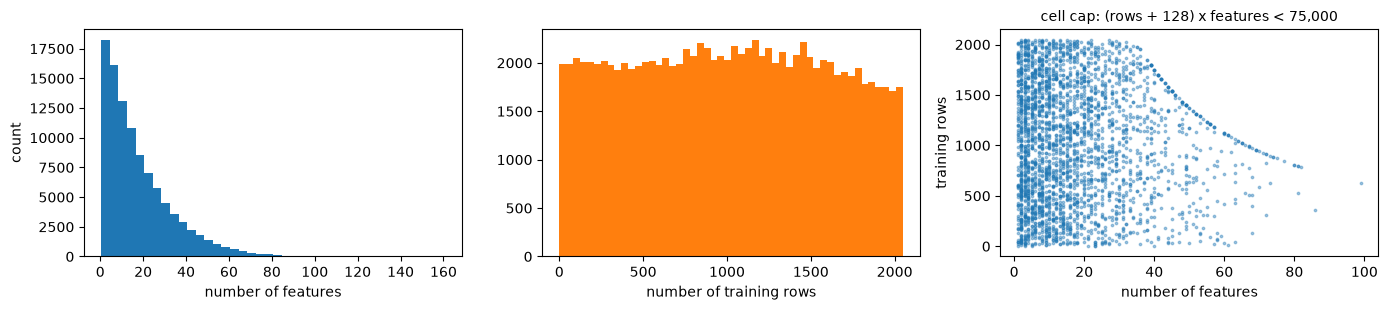

feature 수 중앙값 13, 평균 17.9
feature가 50개를 넘는 데이터셋: 4.7%
셀 수 평균: 19,795


In [5]:
N_VALIDATION = 128


def sample_table_size(rng):
    # 1단계: 학습 행 수 (2,048개까지 균등)
    n_train = int(rng.integers(1, 2049))
    # 2단계: feature 수 (Beta(0.95, 8.0)을 1~160으로 늘린다)
    n_features = 1 + int(round(rng.beta(0.95, 8.0) * 159))
    # 3단계: 셀 수가 75,000개 미만이 되도록 학습 행 수를 줄인다
    max_train = (75_000 - 1) // n_features - N_VALIDATION
    return min(n_train, max_train), n_features


sizes = np.array([sample_table_size(rng) for _ in range(100_000)])
n_train, n_features = sizes[:, 0], sizes[:, 1]
cells = (n_train + N_VALIDATION) * n_features

display(
    pd.DataFrame(
        [sample_table_size(np.random.default_rng(s)) for s in range(5)],
        columns=["학습 행", "feature"],
        index=[f"데이터셋 {s + 1}" for s in range(5)],
    )
)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
axes[0].hist(n_features, bins=np.arange(0.5, 161.5, 4), color="C0")
axes[0].set_xlabel("number of features")
axes[1].hist(n_train, bins=50, color="C1")
axes[1].set_xlabel("number of training rows")
axes[2].scatter(n_features[:3000], n_train[:3000], s=3, alpha=0.4)
axes[2].set_xlabel("number of features")
axes[2].set_ylabel("training rows")
axes[2].set_title("cell cap: (rows + 128) x features < 75,000", fontsize=10)
axes[0].set_ylabel("count")
plt.tight_layout()
plt.show()

print(f"feature 수 중앙값 {np.median(n_features):.0f}, 평균 {n_features.mean():.1f}")
print(f"feature가 50개를 넘는 데이터셋: {np.mean(n_features > 50):.1%}")
print(f"셀 수 평균: {cells.mean():,.0f}")

feature 수는 대부분 수십 개 이하이고, 100개를 넘는 데이터셋은 드뭅니다. feature가 많으면 셀 제한 때문에 행 수가 줄어듭니다(오른쪽 그림의 곡선). 그런데도 v2는 평가 때 feature 500개, 행 10,000개까지 동작합니다. 셀 단위 구조가 학습 때보다 큰 표로 외삽할 수 있기 때문입니다(primer 6절).

v1과 달리 v2 논문에는 BNN prior가 없습니다. 범주형 feature도 v1처럼 연속값 열을 사후에 구간 번호로 바꾸는 대신, 그래프 안의 이산화 노드에서 나오고 그 값이 다른 노드에 영향을 줍니다.

## 5. 학습

| | v1 | v2 |
|---|---|---|
| step × batch | 18,000 × 512 | 약 2,000,000 × 64 |
| 합성 데이터셋 수 | 약 920만 | 약 1억 3,000만 |
| 데이터셋 하나 | 행 1,152개(학습 + 테스트), feature 100열로 채움 | 학습 행 2,048개 이하 + 검증 128개, feature 1~160 |
| 최적화 | Adam, warmup + cosine, lr {1e-3, 3e-4, 1e-4} 중 선택 | Adam, warmup + cosine, lr [1e-4, 5e-4] 중 마지막 학습 loss가 가장 낮은 것 |
| 하드웨어 | RTX 2080 Ti 8장, 20시간 | RTX 2080 Ti 8장, 약 2주 |

손실은 분류면 cross-entropy, 회귀면 bar distribution의 NLL입니다. 분류 모델과 회귀 모델은 따로 학습합니다. 본문은 학습마다 데이터셋을 약 1억 개 만든다고 적었고, Methods의 step 수로 계산하면 약 1억 3,000만 개입니다.

In [6]:
steps, batch = 2_000_000, 64
print(f"합성 데이터셋: {steps * batch:,}개")
print(f"4절의 셀 수 평균으로 계산한 학습 중 셀 수: {steps * batch * cells.mean():.2e}개")
print(f"v1 대비 데이터셋 수: {steps * batch / (18_000 * 512):.0f}배")

합성 데이터셋: 128,000,000개
4절의 셀 수 평균으로 계산한 학습 중 셀 수: 2.53e+12개
v1 대비 데이터셋 수: 14배


## 6. 회귀 출력

회귀 출력은 원 PFN 논문의 bar distribution(Riemann distribution)입니다. 실수 축을 구간으로 나누고, 구간마다 확률을 내서 piece-wise constant 분포를 만듭니다. 양 끝 구간은 half-normal로 바꿔 전체 실수 축을 덮습니다. 원 PFN에서의 구현은 [`01_pfn/03_pfn_implementation_details`](../01_pfn/03_pfn_implementation_details.ipynb)에서 다뤘습니다. v2는 구간 경계를 이렇게 정합니다(Methods "Regression details").

1. 학습 때 회귀 target을 데이터셋마다 z-정규화합니다(평균 0, 표준편차 1).
2. prior에서 데이터셋을 많이 뽑아 정규화한 target을 모으고, 그 분포의 1/5,000 분위수들을 경계로 씁니다. 구간은 5,000개이고, 구간마다 확률이 비슷하게 배정됩니다.
3. 추론 때는 실제 target도 학습 행 기준으로 z-정규화해 넣습니다. 기본 설정은 power transform도 함께 씁니다.
4. 예측한 분포는 정규화를 되돌려야 원래 단위가 됩니다. 이때 확률은 그대로 두고 **구간 경계에만** 역변환을 적용합니다.

4번이 성립하는 이유는 변환이 단조 증가이기 때문입니다. 정규화한 값이 구간 $[b_k, b_{k+1})$에 들어갈 확률은, 원래 값이 구간 $[T^{-1}(b_k), T^{-1}(b_{k+1}))$에 들어갈 확률과 같습니다. 구간 10개로 줄인 예로 따라가 봅니다. 카페의 하루 매출(만 원)을 예측하고, 학습 행의 평균이 85, 표준편차가 20이라고 하겠습니다.

In [7]:
n_buckets = 10  # 실제 v2는 5,000

# 1~2단계: prior에서 모은 "정규화한 target" 대신 표준정규 표본으로 경계를 만든다
prior_targets = rng.standard_normal(200_000)
borders = np.quantile(prior_targets, np.linspace(0, 1, n_buckets + 1))
borders[[0, -1]] = [-4.0, 4.0]  # 양 끝은 보기 좋게 자른다 (실제로는 half-normal 꼬리)

# 모델이 테스트 행 하나에 대해 낸 구간 확률이라고 하자 (설명용 값)
proba = np.array([0.01, 0.02, 0.04, 0.08, 0.15, 0.25, 0.22, 0.13, 0.07, 0.03])

# 3~4단계: 학습 행의 평균·표준편차로 경계만 원래 단위로 되돌린다
train_mean, train_std = 85.0, 20.0
borders_original = borders * train_std + train_mean

display(
    pd.DataFrame(
        {
            "정규화한 구간": [
                f"[{a:.2f}, {b:.2f})" for a, b in zip(borders[:-1], borders[1:], strict=True)
            ],
            "매출 구간 (만 원)": [
                f"[{a:.1f}, {b:.1f})"
                for a, b in zip(borders_original[:-1], borders_original[1:], strict=True)
            ],
            "확률": proba,
        }
    )
)

centers = (borders_original[:-1] + borders_original[1:]) / 2
print(f"예측 평균 ≈ {np.sum(proba * centers):.1f}만 원 (구간 가운데 값의 가중 평균)")

,정규화한 구간,매출 구간 (만 원),확률
0,"[-4.00, -1.28)","[5.0, 59.4)",0.01
1,"[-1.28, -0.84)","[59.4, 68.2)",0.02
2,"[-0.84, -0.52)","[68.2, 74.6)",0.04
3,"[-0.52, -0.25)","[74.6, 80.0)",0.08
4,"[-0.25, 0.00)","[80.0, 85.1)",0.15
5,"[0.00, 0.26)","[85.1, 90.1)",0.25
6,"[0.26, 0.53)","[90.1, 95.6)",0.22
7,"[0.53, 0.85)","[95.6, 101.9)",0.13
8,"[0.85, 1.28)","[101.9, 110.7)",0.07
9,"[1.28, 4.00)","[110.7, 165.0)",0.03


예측 평균 ≈ 89.8만 원 (구간 가운데 값의 가중 평균)


확률 열은 그대로이고 구간 경계만 바뀌었습니다. 분포 전체를 내므로 평균뿐 아니라 분위수나 "매출이 100만 원을 넘을 확률" 같은 값도 바로 읽을 수 있습니다. 쌍봉 분포처럼 평균 하나로는 요약할 수 없는 예측도 표현합니다(8절의 이중 슬릿 실험).

구간 5,000개를 prior target의 분위수로 정하므로, target이 자주 나오는 0 근처에는 구간이 촘촘하고 꼬리 쪽에는 성깁니다. 실제 target을 z-정규화하고 power transform으로 정규분포에 가깝게 펴는 것은, 실제 데이터를 이 촘촘한 영역에 맞춰 넣기 위해서입니다.

## 7. 추론

논문은 추론 파이프라인이 성능에 중요하다고 강조합니다(Methods "Inference details"). 기본 설정은 같은 모델을 전처리만 다르게 해서 여러 번 돌리고 평균하는 작은 앙상블입니다. 분류는 4개, 회귀는 8개입니다. 앙상블 멤버마다 다음을 바꿉니다.

- **feature 순서 섞기**: 모델이 열 순서에 완전히 무관하지는 않기 때문입니다(primer 7절의 열 이름표).
- **클래스 번호 섞기**(분류): v1과 같습니다([v1 walkthrough](../02_tabpfn/03_tabpfn_paper_walkthrough.ipynb) 2.5절).
- **전처리 조합**: 아래 목록 중 일부를 멤버마다 다르게 고릅니다. 정확한 조합은 논문 Extended Data Table 5에 있습니다.

| 전처리 | 하는 일 |
|---|---|
| Quantile + Id | feature를 0~1의 분위수 값으로 바꾼 열을 원래 열 옆에 붙인다 (feature 수가 2배) |
| Category shuffling | 범주 수가 적은 범주형 feature의 번호를 섞는다 |
| SVD | feature의 SVD 압축 성분을 덧붙인다 |
| Outlier removal | 평균에서 표준편차 12배보다 먼 값을 없앤다 |
| Power transform | Yeo-Johnson 변환으로 feature(회귀면 target도)를 정규분포에 가깝게 편다 |
| One-hot encoding | 범주형 feature를 one-hot으로 바꾼다 |

그 밖에도 몇 가지를 더합니다.

- **샘플 식별자**: 표준정규 난수 열을 하나 붙입니다. sample attention은 행 순서에 무관하므로 완전히 같은 행 두 개를 구분할 수 없는데, 이 열이 행마다 다른 값을 줍니다.
- **softmax 온도**: 분류 확률의 calibration을 위해 logit을 $T = 0.9$로 나눈 뒤 softmax합니다.
- **선택 옵션**: feature 쌍 50개까지의 곱(2차 다항 feature), 앙상블 멤버마다 행 일부만 쓰기. 둘 다 기본값은 꺼져 있습니다.

온도 $T = 0.9$가 확률을 어떻게 바꾸는지 봅니다.

In [8]:
logits = np.array([2.0, 1.0, 0.2])


def softmax(z, temperature=1.0):
    e = np.exp((z - z.max()) / temperature)
    return e / e.sum()


display(
    pd.DataFrame(
        {"T = 1.0": softmax(logits, 1.0), "T = 0.9 (v2 기본)": softmax(logits, 0.9)},
        index=["클래스 0", "클래스 1", "클래스 2"],
    ).round(3)
)

,T = 1.0,T = 0.9 (v2 기본)
클래스 0,0.652,0.683
클래스 1,0.240,0.225
클래스 2,0.108,0.092


$T < 1$이면 가장 큰 확률이 조금 더 커지고, 확률의 순서는 그대로입니다. 기본값 0.9는 다른 추론 설정과 함께 개발용 데이터셋에서 고른 값입니다(Methods "Default configuration of TabPFN").

기본 설정 외에 시간을 더 쓸 수 있으면 두 가지 방법이 있습니다.

- **TabPFN (PHE)**: 전처리·모델 설정의 포트폴리오에서 여러 TabPFN을 holdout 검증으로 평가하고, greedy ensemble selection(25회 반복)으로 가중 평균합니다. 가중치가 0인 멤버는 버립니다.
- **랜덤 트리로 데이터 나누기**: 이질적인 큰 데이터셋을 결정 트리로 나눠, 잎(최소 500~2,000행)마다 TabPFN을 따로 씁니다. TabPFN이 작은 데이터셋에서 가장 잘하기 때문입니다. HPO와 PHE에서만 씁니다.

## 8. 정성 분석 — toy 문제

![TabPFN v2 Figure 3](images/tabpfn_v2_fig3.png)

*그림: 논문 Fig. 3 (Hollmann et al. 2025, [Nature 637:319](https://doi.org/10.1038/s41586-024-08328-6), CC BY 4.0). (a) feature 하나짜리 toy 함수 6개에서 기본 설정 모델들의 예측(파랑)과 정답(주황). (b) 이중 슬릿 실험에서 광자가 벽에 닿는 위치의 분포. 슬릿 폭과 간격이 feature입니다.*

- 선형 회귀는 선형 함수만, MLP는 매끄러운 함수만 잘 맞춥니다. MLP는 계단 함수에서 특히 약합니다.
- CatBoost(나무 계열)는 계단 모양으로만 맞춰서 오차가 생기지만, 크게 틀리지는 않습니다.
- TabPFN은 매끄러운 함수와 계단 함수를 모두 맞추고, 노이즈의 크기가 x에 따라 다른 경우(heteroscedastic)에는 예측 분포의 폭도 따라 바뀝니다.
- 이중 슬릿 실험의 간섭 무늬처럼 봉우리가 여러 개인 분포를 forward pass 한 번(1.2초)으로 예측합니다. CatBoost는 분위수마다 모델을 따로 학습해 분포를 이어 붙여야 하고, 튜닝해도 결과가 더 나쁩니다(기본 설정은 169.3초).

계단 함수를 맞추는 능력은 prior의 결정 나무 간선과 계단 활성화([`02_prior_primer`](02_prior_primer.ipynb) 3절)에서, 분포를 내는 능력은 bar distribution 출력(6절)에서 옵니다.

## 9. 정량 분석 — benchmark

### 9.1 평가 방법

- **데이터셋**: AutoML Benchmark의 분류 29개, AutoML Benchmark와 OpenML-CTR23의 회귀 28개입니다. 샘플 10,000개, feature 500개, 클래스 10개 이하인 것을 모두 골랐습니다. prior와 하이퍼파라미터는 이와 겹치지 않는 개발용 데이터셋으로 정했습니다.
- **반복**: 데이터셋마다 OpenML이 정한 split 10개(학습 90%, 테스트 10%)의 평균입니다.
- **지표**: 분류는 ROC AUC(one-vs-rest)와 accuracy, 회귀는 $R^2$와 negative RMSE입니다.
- **baseline**: random forest, XGBoost, CatBoost, LightGBM, 선형 모델, SVM, MLP입니다. 튜닝은 5-fold 교차검증의 무작위 탐색이고, 시간 예산은 30초부터 4시간까지입니다.
- **하드웨어**: 모든 방법에 CPU 8코어를 주고, TabPFN은 RTX 2080 Ti 한 장을 더 씁니다. baseline에 GPU를 줘도 작은 데이터셋이라 나아지지 않았습니다(Extended Data Fig. 2d).

v1 논문(5 split, 학습 50%)과 프로토콜이 다르므로 두 논문의 수치를 직접 비교할 수는 없습니다.

### 9.2 정규화한 점수 읽기

v2 논문의 주요 수치는 데이터셋마다 정규화한 점수의 평균입니다. 데이터셋마다 비교한 방법 중 가장 좋은 점수를 1, 가장 나쁜 점수를 0으로 놓고 선형으로 옮깁니다. 데이터셋마다 점수 범위가 달라도 평균을 낼 수 있게 하려는 것입니다. 데이터셋 2개, 방법 3개로 따라가 봅니다(설명용 값).

In [9]:
raw = pd.DataFrame(
    {"데이터셋 A": [0.95, 0.93, 0.90], "데이터셋 B": [0.71, 0.74, 0.65]},
    index=["TabPFN", "CatBoost", "RF"],
)


def normalize(scores):
    # 데이터셋(열)마다 가장 좋은 점수 → 1, 가장 나쁜 점수 → 0
    return (scores - scores.min()) / (scores.max() - scores.min())


print("원래 ROC AUC")
display(raw.assign(평균=raw.mean(axis=1)).round(3))
print("정규화한 점수")
norm = normalize(raw)
display(norm.assign(평균=norm.mean(axis=1)).round(3))

# 약한 방법 하나를 더하면?
with_linear = pd.concat(
    [raw, pd.DataFrame({"데이터셋 A": [0.80], "데이터셋 B": [0.60]}, index=["Linear"])]
)
norm2 = normalize(with_linear)
print("약한 방법(Linear)을 더해 정규화한 점수")
display(norm2.assign(평균=norm2.mean(axis=1)).round(3))

원래 ROC AUC


,데이터셋 A,데이터셋 B,평균
TabPFN,0.95,0.71,0.830
CatBoost,0.93,0.74,0.835
RF,0.90,0.65,0.775


정규화한 점수


,데이터셋 A,데이터셋 B,평균
TabPFN,1.0,0.667,0.833
CatBoost,0.6,1.000,0.800
RF,0.0,0.000,0.000


약한 방법(Linear)을 더해 정규화한 점수


,데이터셋 A,데이터셋 B,평균
TabPFN,1.000,0.786,0.893
CatBoost,0.867,1.000,0.933
RF,0.667,0.357,0.512
Linear,0.000,0.000,0.000


세 가지를 볼 수 있습니다.

- 원래 점수의 평균은 CatBoost가 0.005 높지만, 정규화하면 TabPFN이 0.033 높습니다. 정규화는 데이터셋마다의 순위와 상대 거리만 남기므로, 점수 범위가 좁은 데이터셋 A의 작은 차이가 데이터셋 B의 큰 차이와 같은 무게를 가집니다.
- 가장 나쁜 방법(RF)은 원래 점수가 0.775인데 정규화하면 0이 됩니다.
- 약한 방법(Linear)을 하나 더하면 모든 점수가 바뀌고, TabPFN과 CatBoost의 순서까지 뒤집힙니다. 정규화한 점수는 비교에 넣은 방법들에 따라 달라집니다.

그래서 "TabPFN 0.939, CatBoost 0.752"는 이 baseline 집합 안에서의 상대적 위치로 읽어야 하고, ROC AUC가 0.19 높다는 뜻이 아닙니다. 데이터셋별 정규화 전 점수는 논문 Supplementary Tables 1~4에 있고, 이 저장소의 재현도 정규화 전 점수로 비교합니다.

### 9.3 결과

![TabPFN v2 Figure 4](images/tabpfn_v2_fig4.png)

*그림: 논문 Fig. 4 (Hollmann et al. 2025, [Nature 637:319](https://doi.org/10.1038/s41586-024-08328-6), CC BY 4.0). (a) 기본 설정(진한 색)과 4시간 튜닝(옅은 색)의 정규화 점수. 위가 분류, 아래가 회귀입니다. (b) 데이터셋별로 TabPFN과 CatBoost를 비교한 것으로, 대각선 아래 점은 TabPFN이 나은 데이터셋입니다. (c) 튜닝 시간에 따른 정규화 점수.*

| | TabPFN | CatBoost (가장 강한 기본 설정 baseline) |
|---|---|---|
| 분류, 기본 설정 (정규화 ROC AUC) | 0.939 | 0.752 |
| 분류, 튜닝 (정규화 ROC AUC) | 0.952 | 0.822 |
| 회귀, 기본 설정 (정규화 negative RMSE) | 0.923 | 0.872 |
| 회귀, 튜닝 (정규화 negative RMSE) | 0.968 | 0.875 |

기본 설정 TabPFN은 분류 평균 2.8초, 회귀 4.8초가 걸리고, 4시간 튜닝한 모든 baseline보다 좋습니다. 논문의 "5,140배, 3,000배 빠르다"는 이 시간을 4시간(14,400초)과 비교한 값입니다.

In [10]:
tuning_budget = 4 * 60 * 60  # baseline의 튜닝 시간 4시간
for task, seconds in [("분류", 2.8), ("회귀", 4.8)]:
    print(f"{task}: {tuning_budget / seconds:,.0f}배")

분류: 5,143배
회귀: 3,000배


2.8초가 반올림한 값이라 계산하면 5,143배로 조금 다릅니다. 데이터셋별로 보면 CatBoost가 나은 데이터셋도 있지만 TabPFN이 대부분에서 이깁니다(Fig. 4b). 그 밖의 결과는 다음과 같습니다.

| 실험 | 결과 |
|---|---|
| AutoGluon 1.0과 비교 (Fig. 5c, d) | 분류: 기본 설정 TabPFN(2.8초)이 4시간 AutoGluon보다 좋고, TabPFN (PHE)는 정규화 ROC AUC 0.971(기본 0.939, AutoGluon 0.914). 회귀: TabPFN (PHE)가 최소 예산 300초에서 4시간 AutoGluon을 넘음(48배) |
| Grinsztajn benchmark (Extended Data Fig. 2a, b) | 나무 계열이 강하다고 알려진 benchmark에서도 TabPFN이 가장 좋음 |
| TabZilla 102개 (Extended Data Fig. 2c) | 같은 결론 |
| Kaggle Tabular Playground 5개 (Extended Data Table 6) | 기본 설정끼리 비교에서 5개 모두 CatBoost보다 좋음 |

## 10. 강건성과 foundation model 기능

### 10.1 데이터 특성에 대한 강건성 (Fig. 5a, b)

- **무의미한 feature**: 원래 feature를 섞어 만든 무의미한 열을 더해도 성능이 크게 떨어지지 않습니다. v1(부록 B.3.2)과 MLP의 약점이었던 부분입니다.
- **이상치**: 셀마다 2% 확률로 무작위 배수를 곱해도 강건합니다.
- **샘플·feature 줄이기**: 모든 방법의 성능이 떨어지지만, 학습 샘플을 절반만 써도 TabPFN은 전체 샘플을 쓴 CatBoost만큼 합니다.
- **하위 그룹**: 범주형 feature 유무, 결측값 유무, 샘플 수, feature 수로 데이터셋을 나눠 봐도 상대 성능이 크게 달라지지 않습니다. 단 논문은 이 결과가 10,000행·500 feature를 넘는 데이터셋에서도 잘 된다는 뜻은 아니라고 적었습니다.

[`02_prior_primer`](02_prior_primer.ipynb) 8절에 이 결과들과 prior 구성 요소의 짝을 정리했습니다.

### 10.2 foundation model 기능 (Fig. 6)

| 기능 | 방법 |
|---|---|
| 밀도 추정 | 분류·회귀 모델로 $p(x, y \mid D) = \prod_j p(x_j \mid x_{<j}, D) \cdot p(y \mid x, D)$를 feature 하나씩 예측해 곱한다. feature 순서 24개로 평균해 순서 의존을 줄인다. 이상치 탐지에 쓸 수 있다 |
| 데이터 생성 | 같은 분해를 따라 feature를 하나씩 샘플링한다 |
| 임베딩 | 마지막 층의 y 토큰을 행의 표현으로 쓴다. mfeat-factors에서 원래 feature보다 클래스가 잘 나뉜다 |
| fine-tuning | 비슷한 데이터셋들로 가중치를 더 학습한다. 사인 곡선 데이터셋 50번 실험에서 분포가 비슷할수록 이득이 크다 |
| 해석 | SHAP으로 feature 중요도를 계산한다 |

밀도 추정과 생성이 되는 이유는 feature 하나를 target으로 바꿔 넣어도 같은 모델이 그대로 쓰이기 때문입니다. 셀 단위 구조라 어느 열이든 "예측할 열"로 정할 수 있습니다.

## 11. 한계

논문 Methods의 "Limitations of TabPFN"과 본문의 언급을 모으면 다음과 같습니다.

1. **예측 한 번은 느립니다.** 행 10,000개·열 10개 데이터셋에서 샘플 하나를 예측하는 데 0.2초(GPU 없이 0.6초)가 걸리고, CatBoost는 0.0002초입니다. 실시간 추론용으로 최적화되지 않았습니다.
2. **메모리가 데이터셋 크기에 비례합니다.** 아주 큰 데이터셋에서는 부담이 됩니다.
3. **평가 범위는 행 10,000개, feature 500개까지입니다.** 더 큰 데이터셋, 매끄럽지 않은 회귀 데이터셋에서는 CatBoost, XGBoost, AutoGluon이 나을 수 있다고 적었습니다.
4. **클래스는 10개까지입니다.** prior가 클래스 10개 이하의 target만 만들기 때문입니다. 더 많으면 one-vs-rest, one-vs-one, ECOC 같은 방법을 써야 합니다.

## 12. 이 저장소의 재현 계획

v1은 공식 v1 코드에 prior 수치까지 있어서 논문 규모로 다시 학습해 Table 1을 재현했습니다([`02_tabpfn/04`](../02_tabpfn/04_tabpfn_reproduction.ipynb)). v2는 prior 코드가 없어서, 공개된 TabICL prior로 학습합니다. 판정은 v1처럼 논문 수치로 합니다. 같은 benchmark(분류 29개, 회귀 28개, OpenML 10-fold)에서 직접 학습한 모델의 점수를 논문 Supplementary Tables 1·2의 TabPFN 점수와 비교합니다.

| 단계 | 하는 일 | 확인하는 것 |
|---|---|---|
| 1. 구조와 추론 | 논문 Methods대로 `src/minipfn/tabpfn_v2/`에 구조(`model.py`)와 추론 앙상블(`inference.py`)을 만든다 | [`01_two_way_attention_primer`](01_two_way_attention_primer.ipynb)의 성질(학습 행 순서, 테스트 행 독립 등)이 성립하는가 |
| 2. prior | TabICL prior(BSD-3)에 논문의 데이터셋 크기 규칙(4절)과 후처리를 붙인다 | 만든 데이터셋이 4절의 분포를 따르는가, 생성 속도가 학습에 충분한가 |
| 3. 학습 | 논문 규모(약 200만 step × 64)로 분류·회귀 모델을 각각 처음부터 학습한다 | 학습 곡선 |
| 4. 평가 | benchmark 57개 × 10 fold (`scripts/eval_tabpfn_v2.py`) | 논문 TabPFN 점수와 얼마나 차이 나는가 |

## 13. 정리

| 논문 | 핵심 | 이 저장소 |
|---|---|---|
| 본문, Fig. 1 | 합성 데이터셋으로 한 번 학습하고, 실제 데이터셋은 forward pass 한 번으로 분류·회귀한다 | 2절 |
| Methods: 아키텍처 | 셀 단위 토큰, feature attention ↔ sample attention, 테스트 행은 학습 행만, 열 이름표, 셀 2개 묶기, 학습 행 캐시 | [`01_two_way_attention_primer`](01_two_way_attention_primer.ipynb), 3절 |
| Methods: prior | GNR 그래프, 벡터 노드, 신경망·나무·이산화 간선, 원형, 후처리, 결측값 | [`02_prior_primer`](02_prior_primer.ipynb), 4절 |
| Methods: 학습 | 약 200만 step × 64, 학습 행 2,048개 이하 + 검증 128개, feature 1~160, 셀 75,000개 미만 | 4절, 5절 |
| Methods: 회귀 | 구간 5,000개 bar distribution, 경계는 prior target의 분위수, 역변환은 경계에만 | 6절 |
| Methods: 추론 | 4개(회귀 8개) 앙상블, feature·클래스 섞기, 전처리 조합, 온도 0.9, 샘플 식별자 | 7절 |
| Fig. 3~5 | toy 함수와 분포 예측, AMLB·CTR23에서 4시간 튜닝한 baseline보다 좋음, 강건성 | 8~10절 |